In [1]:
import requests
import json
import matplotlib.pyplot as plt

In [2]:
# 동영상 ID
video_id = "j_V6PTcCQCc"

In [3]:
start = 40
end = 97

In [4]:
json_path = f'/source/ms/highlight/json/{video_id}.json'

In [5]:
# url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# # API 호출하여 JSON 데이터 가져오기
# print('get url!!!')
# response = requests.get(url)
# print('get url finished!!!!!')
# data = response.json()

In [6]:
# with open(json_path, 'w') as json_file:
#     json.dump(data, json_file)

In [7]:
with open(json_path, 'r') as json_file:
    data = json.load(json_file)

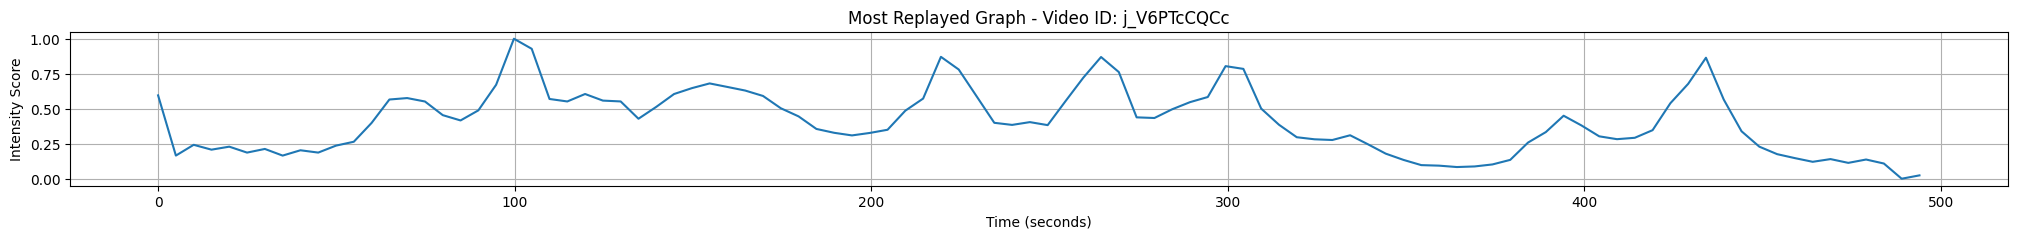

In [10]:
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


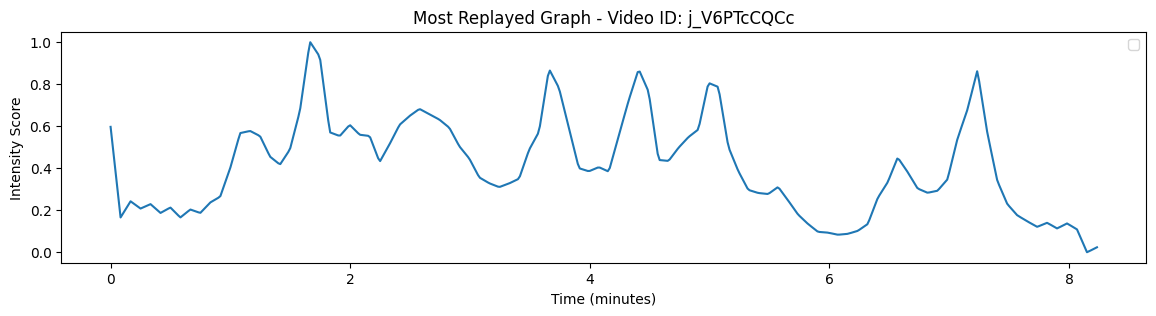

In [11]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
total_duration_minutes = total_duration_seconds 
new_time = np.arange(0, total_duration_minutes, 1) 
# new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
# peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(14, 3))
plt.plot(new_time / 60, smoothed_intensity_scores)  # 분으로 변환하여 표시
# plt.plot(np.array(event_lst) , smoothed_intensity_scores[event_lst], "o", label='evnet')
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
# plt.grid(True)
# plt.xticks(np.arange(0, total_duration_minutes + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.show()

# 소리 크기

In [14]:
audio_path = "./america_god/audio.wav"

In [15]:
from moviepy.editor import VideoFileClip
import librosa
import numpy as np
import matplotlib.pyplot as plt

# 비디오 파일 경로
video_path = f"./america_god/{video_id}.mp4"

# 비디오에서 오디오 추출
video = VideoFileClip(video_path)
audio = video.audio
audio.write_audiofile(audio_path)



# 임시 오디오 파일 삭제
import os
# os.remove("temp_audio.wav")

MoviePy - Writing audio in ./america_god/audio.wav


MoviePy - Done.


In [16]:
# 오디오 파일 로드
# y, sr = librosa.load("soccer.wav")
y, sr = librosa.load(audio_path)

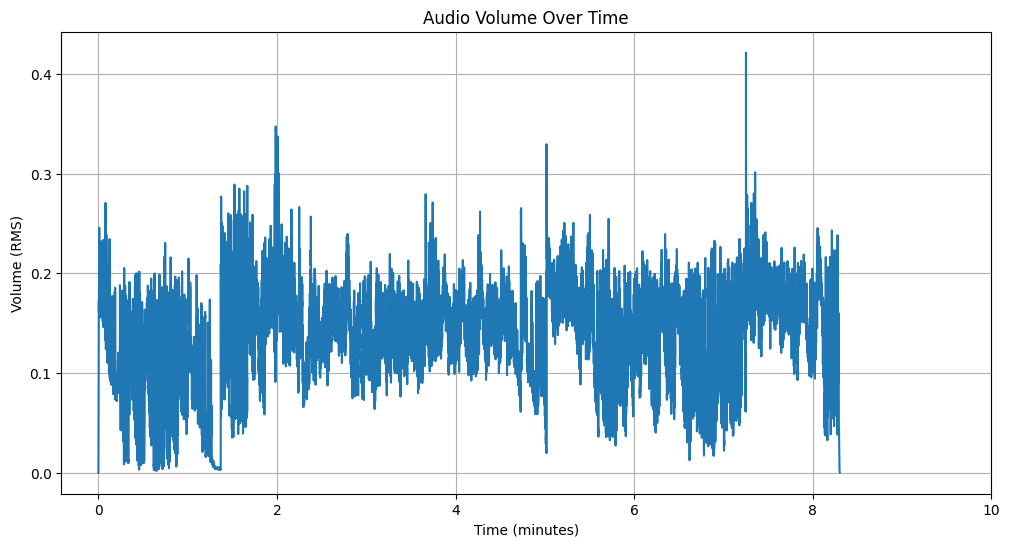

In [17]:


# 소리 크기(RMS) 계산
frame_length = int(sr * 0.05)  # 50ms 프레임
hop_length = int(sr * 0.025)  # 25ms 홉
rms = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)
rms = rms.squeeze()  # 2D에서 1D로 변환

# 시간 배열 생성 (분 단위)
times = librosa.times_like(rms, sr=sr, hop_length=hop_length) / 60

# 그래프 그리기
plt.figure(figsize=(12, 6))
plt.plot(times, rms)
plt.title("Audio Volume Over Time")
plt.xlabel("Time (minutes)")
plt.ylabel("Volume (RMS)")
plt.grid(True)

# x축 눈금 설정 (5분 간격)
max_time = times[-1]
plt.xticks(np.arange(0, max_time + 2, 2))

plt.show()

# Moving average

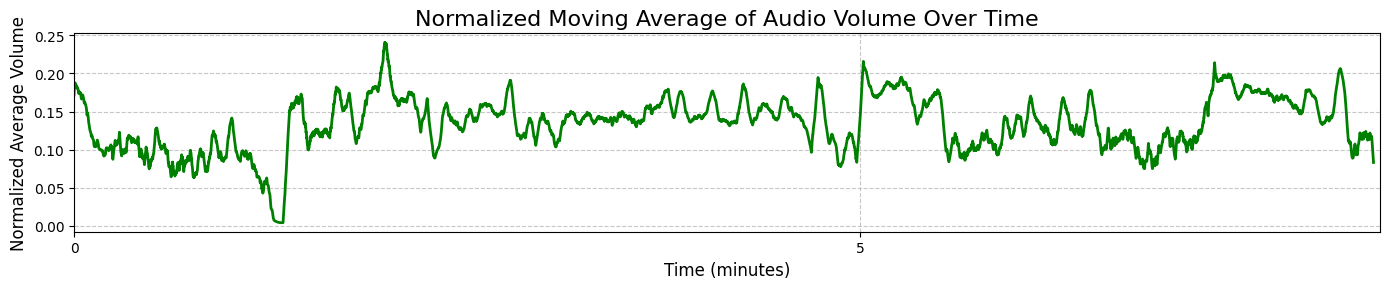

In [22]:
import numpy as np
import matplotlib.pyplot as plt

def moving_average(data, window_size):
    return np.convolve(data, np.ones(window_size), 'valid') / window_size

def normalize(data):
    return (data - np.min(data)) / (np.max(data) - np.min(data))

window_size = 100  # 조절 가능
ma_rms = moving_average(rms, window_size)

# 0과 1 사이로 정규화

# 결과를 완전히 왼쪽으로 이동
ma_times = times[:len(ma_rms)]

plt.figure(figsize=(14, 3))
plt.plot(ma_times, ma_rms, color='green', linewidth=2)
plt.title("Normalized Moving Average of Audio Volume Over Time", fontsize=16)
plt.xlabel("Time (minutes)", fontsize=12)
plt.ylabel("Normalized Average Volume", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(0, max_time + 5, 5))
# plt.ylim(0, 1)  # y축 범위를 0에서 1로 설정
plt.xlim(0, max_time)  # x축 범위를 0부터 max_time까지로 설정
plt.tight_layout()
plt.show()

In [23]:
def crop_data(times, data, start_time, end_time):
    mask = (times >= start_time) & (times <= end_time)
    return times[mask], data[mask]

In [24]:
# start_time = 40  # 시작 시간 (분)
# end_time = 97    # 종료 시간 (분)

# # Most Replayed 데이터 크롭
# new_time_cropped, scores_cropped = crop_data(new_time / 60, smoothed_intensity_scores, start_time, end_time)

# # Moving Average 데이터 크롭
# ma_times_cropped, ma_rms_cropped = crop_data(ma_times, ma_rms, start_time, end_time)



In [25]:
# normalize_scores_cropped = normalize(scores_cropped)
# normalize_ma_rms_cropped = normalize(ma_rms_cropped)

In [26]:
normalize_scores = normalize(smoothed_intensity_scores)
normalize_ma_rms = normalize(ma_rms)

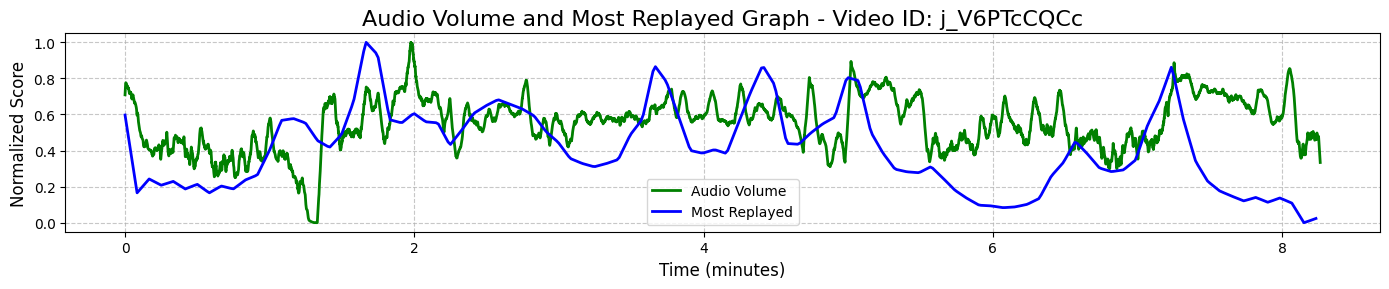

In [27]:
plt.figure(figsize=(14, 3))

# 오디오 볼륨 그래프
plt.plot(ma_times, normalize_ma_rms, color='green', linewidth=2, label='Audio Volume')

# Most Replayed 그래프
plt.plot(new_time/60 , normalize_scores, color='blue', linewidth=2, label='Most Replayed')


plt.title(f'Audio Volume and Most Replayed Graph - Video ID: {video_id}', fontsize=16)
plt.xlabel('Time (minutes)', fontsize=12)
plt.ylabel('Normalized Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
# plt.xticks(np.arange(start_time, end_time + 1, 5))  # 5분 간격으로 x축 눈금 표시
# plt.xlim(start_time, end_time)  # x축 범위 설정
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
def crop_data(times, data, start_time, end_time):
    mask = (times >= start_time) & (times <= end_time)
    return times[mask], data[mask]

Pearson 상관계수: 0.25424238877246436
P-value: 9.65007628540344e-09


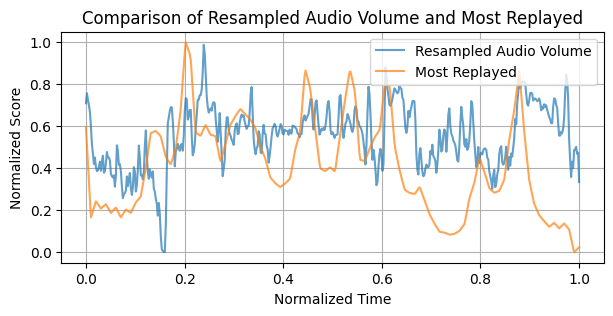

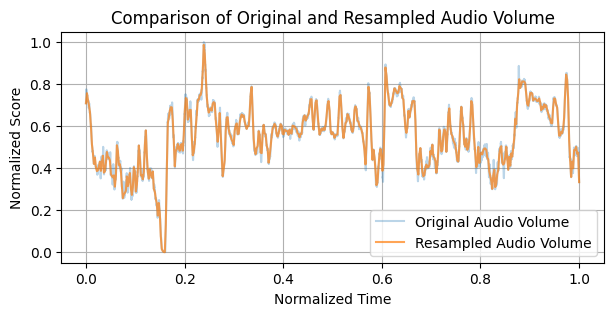

In [29]:
import numpy as np
from scipy import interpolate, stats
import matplotlib.pyplot as plt

# 리샘플링 함수
def resample(x, y, num_points):
    f = interpolate.interp1d(x, y, kind='linear', fill_value='extrapolate')
    x_new = np.linspace(x.min(), x.max(), num_points)
    y_new = f(x_new)
    return x_new, y_new

# 원본 데이터의 x 축 (시간) 생성
x_ma_rms = np.linspace(0, 1, len(normalize_ma_rms))
x_scores = np.linspace(0, 1, len(normalize_scores))

# normalize_ma_rms를 normalize_scores의 길이에 맞춰 리샘플링
x_resampled, y_resampled = resample(x_ma_rms, normalize_ma_rms, len(normalize_scores))

# Pearson 상관계수 계산
correlation, p_value = stats.pearsonr(y_resampled, normalize_scores)

print(f"Pearson 상관계수: {correlation}")
print(f"P-value: {p_value}")

# 시각화
plt.figure(figsize=(7, 3))
plt.plot(x_resampled, y_resampled, label='Resampled Audio Volume', alpha=0.7)
plt.plot(x_scores, normalize_scores, label='Most Replayed', alpha=0.7)
plt.title('Comparison of Resampled Audio Volume and Most Replayed')
plt.xlabel('Normalized Time')
plt.ylabel('Normalized Score')
plt.legend()
plt.grid(True)
plt.show()

# 원본 데이터와 리샘플링된 데이터 비교 (선택적)
plt.figure(figsize=(7, 3))
plt.plot(x_ma_rms, normalize_ma_rms, label='Original Audio Volume', alpha=0.3)
plt.plot(x_resampled, y_resampled, label='Resampled Audio Volume', alpha=0.7)
plt.title('Comparison of Original and Resampled Audio Volume')
plt.xlabel('Normalized Time')
plt.ylabel('Normalized Score')
plt.legend()
plt.grid(True)
plt.show()

## 다른 상관 계수

In [30]:
from dcor import distance_correlation

dcor = distance_correlation(y_resampled, normalize_scores)
print(f"Distance correlation: {dcor}")

Distance correlation: 0.29429492110262645


In [31]:
from scipy import stats

spearman_corr, spearman_p = stats.spearmanr(y_resampled, normalize_scores)
print(f"Spearman 상관계수: {spearman_corr}")
print(f"Spearman P-value: {spearman_p}")

Spearman 상관계수: 0.2743374056616841
Spearman P-value: 5.377156445813332e-10


In [32]:
kendall_tau, kendall_p = stats.kendalltau(y_resampled, normalize_scores)
print(f"Kendall's tau: {kendall_tau}")
print(f"Kendall's tau P-value: {kendall_p}")

Kendall's tau: 0.18550689077004867
Kendall's tau P-value: 6.868578900805449e-10


In [33]:
from sklearn.metrics import mutual_info_score

mi = mutual_info_score(y_resampled, normalize_scores)
print(f"Mutual Information: {mi}")

Mutual Information: 6.20455776256869


In [34]:
from minepy import MINE

mine = MINE()
mine.compute_score(y_resampled, normalize_scores)
print(f"Maximal Information Coefficient: {mine.mic()}")

Maximal Information Coefficient: 0.26691712783794597


In [35]:
from sklearn.metrics.pairwise import cosine_similarity

cos_sim = cosine_similarity(y_resampled.reshape(1, -1), normalize_scores.reshape(1, -1))[0][0]
print(f"Cosine Similarity: {cos_sim}")

Cosine Similarity: 0.8838751743854898
